In [2]:
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from time import time
from torchvision import datasets, transforms
from torch import nn, optim


Aqui você carrega:


* PyTorch → framework de Deep Learning
* torchvision → datasets de imagens
* matplotlib → mostrar imagens
* numpy → operações matemáticas

In [6]:
transform = transforms.ToTensor() #definindo a conversao de imagem para tensor

trainset = datasets.MNIST('./MNIST_data/', download=True, train=True, transform=transform) # Carrega a parte de treino do dataset
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True) # Cria um buffer para pegar os dados por partes

valset = datasets.MNIST('./MNIST_data/', download=True, train=False, transform=transform) # Carrega a parte de validação do dataset
valloader = torch.utils.data.DataLoader(valset, batch_size=64, shuffle=True) # Cria um buffer para pegar os dados por partes

MNIST é um banco de imagens de números escritos à mão:

* 0 até 9
* imagens 28×28 pixels
* dataset clássico para aprender redes neurais

O modelo não entende imagem “normal”.
Ele precisa de tensores.

Tensor = estrutura matemática usada pelo PyTorch.

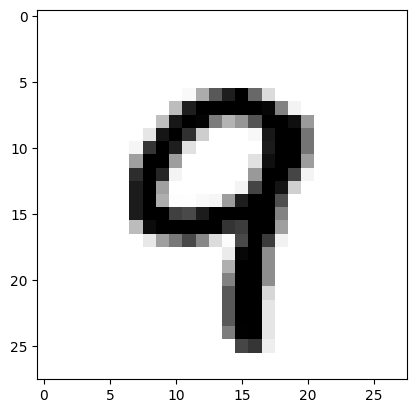

In [8]:
dataiter = iter(trainloader)
imagens, etiquetas = next(dataiter)
plt.imshow(imagens[0].numpy().squeeze(), cmap='gray_r')

In [10]:
class Modelo(nn.Module):

    def __init__(self):
        super(Modelo, self).__init__()

        self.linear1 = nn.Linear(28*28, 128)  # camada de entrada
        self.linear2 = nn.Linear(128, 64)     # camada interna 1
        self.linear3 = nn.Linear(64, 10)      # camada de saída

    def forward(self, X):

        X = F.relu(self.linear1(X))  # ativação da entrada -> camada interna 1
        X = F.relu(self.linear2(X))  # ativação da interna 1 -> interna 2
        X = self.linear3(X)          # saída

        return F.log_softmax(X, dim=1)

In [11]:
def treino(modelo, trainloader, device):

    otimizador = optim.SGD(
        modelo.parameters(),
        lr=0.01,
        momentum=0.5
    )

    inicio = time()

    criterio = nn.NLLLoss()

    EPOCHS = 10

    modelo.train()

    for epoch in range(EPOCHS):

        perda_acumulada = 0

        for imagens, etiquetas in trainloader:

            imagens = imagens.view(imagens.shape[0], -1)

            otimizador.zero_grad()

            output = modelo(imagens.to(device))

            perda_instantanea = criterio(
                output,
                etiquetas.to(device)
            )

            perda_instantanea.backward()

            otimizador.step()

            perda_acumulada += perda_instantanea.item()

        else:
            print(
                "Epoch {} - Perda resultante: {}".format(
                    epoch + 1,
                    perda_acumulada / len(trainloader)
                )
            )

    print(
        "\nTempo de treino (em minutos) =",
        (time() - inicio) / 60
    )


def validacao(modelo, valloader, device):

    conta_corretas = 0
    conta_todas = 0

    modelo.eval()

    for imagens, etiquetas in valloader:

        for i in range(len(etiquetas)):

            img = imagens[i].view(1, 784)

            with torch.no_grad():

                logps = modelo(img.to(device))

            ps = torch.exp(logps)

            probab = list(ps.cpu().numpy()[0])

            etiqueta_pred = probab.index(max(probab))

            etiqueta_certa = etiquetas.numpy()[i]

            if etiqueta_certa == etiqueta_pred:
                conta_corretas += 1

            conta_todas += 1

    print("Total de imagens testadas =", conta_todas)

    print(
        "\nPrecisão do modelo = {}%".format(
            conta_corretas * 100 / conta_todas
        )
    )

In [12]:
modelo = Modelo()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

modelo.to(device)

Modelo(
  (linear1): Linear(in_features=784, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=64, bias=True)
  (linear3): Linear(in_features=64, out_features=10, bias=True)
)

In [13]:
treino(modelo, trainloader, device)
validacao(modelo, valloader, device)

Epoch 1 - Perda resultante: 1.1839668956329066
Epoch 2 - Perda resultante: 0.38327008071961177
Epoch 3 - Perda resultante: 0.31190020506824256
Epoch 4 - Perda resultante: 0.2706710160699989
Epoch 5 - Perda resultante: 0.23983735669015058
Epoch 6 - Perda resultante: 0.21549242828637044
Epoch 7 - Perda resultante: 0.1953865582389491
Epoch 8 - Perda resultante: 0.17820743041267909
Epoch 9 - Perda resultante: 0.16346422383494214
Epoch 10 - Perda resultante: 0.15110151999310326

Tempo de treino (em minutos) = 1.420271841684977
Total de imagens testadas = 10000

Precisão do modelo = 95.64%


In [14]:
print(modelo)

Modelo(
  (linear1): Linear(in_features=784, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=64, bias=True)
  (linear3): Linear(in_features=64, out_features=10, bias=True)
)


Previsão: 2
Valor correto: 6


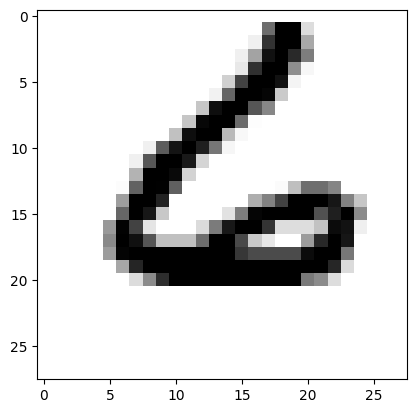

In [18]:
dataiter = iter(valloader)
imagens, etiquetas = next(dataiter)

img = imagens[11].view(1, 784).to(device)

with torch.no_grad():
    logps = modelo(img)

ps = torch.exp(logps)

probab = list(ps.cpu().numpy()[0])

predicao = probab.index(max(probab))

print("Previsão:", predicao)
print("Valor correto:", etiquetas[0].item())

plt.imshow(imagens[0].numpy().squeeze(), cmap='gray_r')
plt.show()

Imagem 0
Previsão: 6
Correto: 6


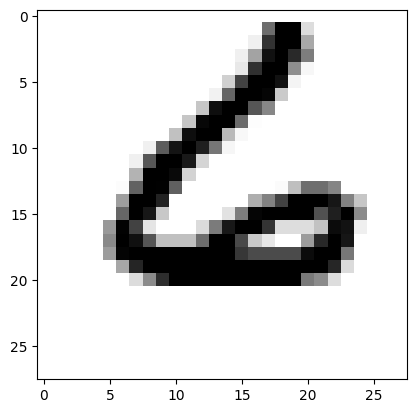

Imagem 1
Previsão: 3
Correto: 3


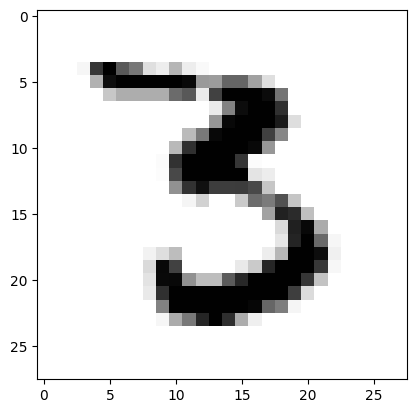

Imagem 2
Previsão: 9
Correto: 9


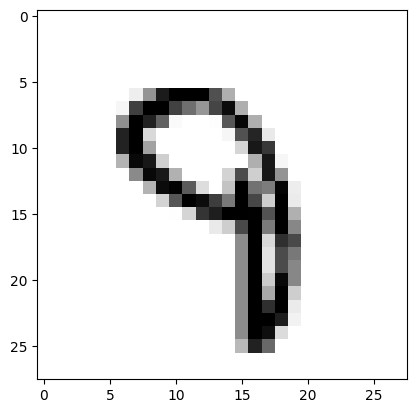

Imagem 3
Previsão: 4
Correto: 4


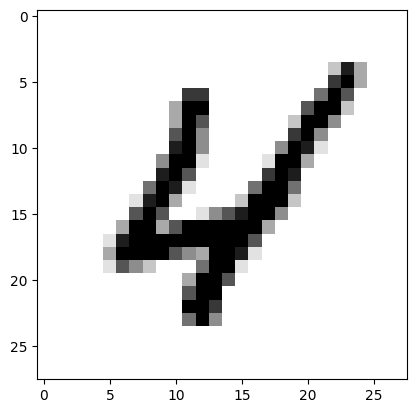

Imagem 4
Previsão: 2
Correto: 2


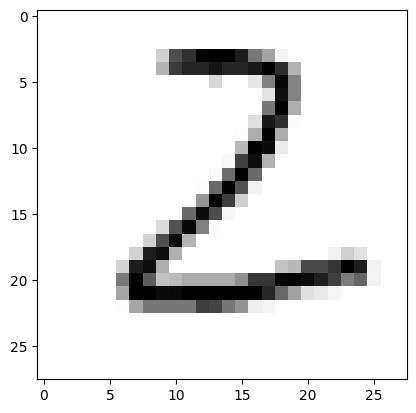

Imagem 5
Previsão: 9
Correto: 9


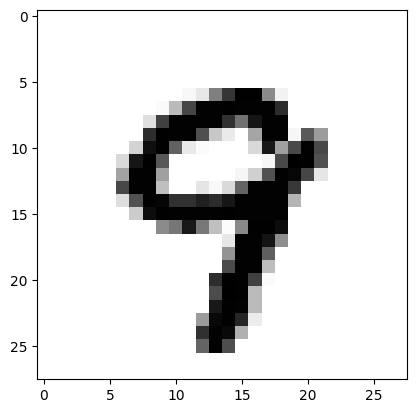

Imagem 6
Previsão: 5
Correto: 5


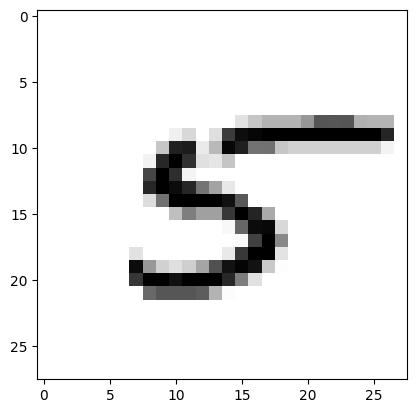

Imagem 7
Previsão: 5
Correto: 5


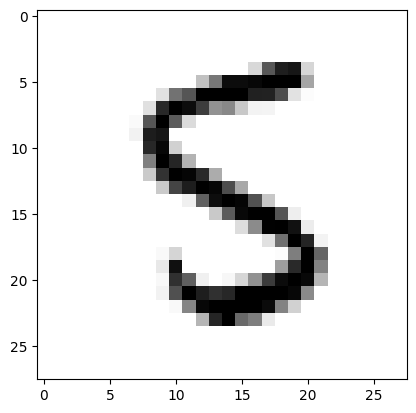

Imagem 8
Previsão: 1
Correto: 1


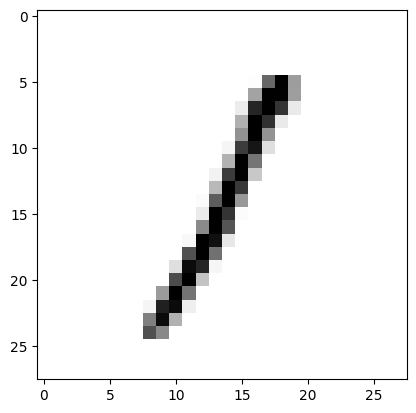

Imagem 9
Previsão: 6
Correto: 6


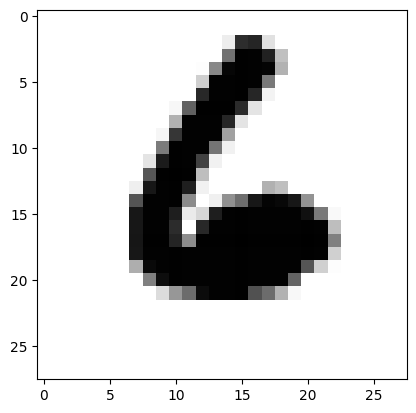

In [19]:
for i in range(10):

    img = imagens[i].view(1, 784).to(device)

    with torch.no_grad():
        logps = modelo(img)

    ps = torch.exp(logps)
    probab = list(ps.cpu().numpy()[0])

    predicao = probab.index(max(probab))

    print("Imagem", i)
    print("Previsão:", predicao)
    print("Correto:", etiquetas[i].item())

    plt.imshow(imagens[i].numpy().squeeze(), cmap='gray_r')
    plt.show()